# ML Assignment 2 – Breast Cancer Classification

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI — 569 rows, 30 numeric features, binary target.

**Source:** https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic (loaded with `sklearn.datasets.load_breast_cancer`).

**Models:** Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM.

**Metrics:** Accuracy, AUC, Precision, Recall, F1, MCC.

## 1. Setup

In [1]:
#libraries
import os, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

#sklearn data, models and metrics
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42  #fixed seed for split and models
print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.6.1


## 2. Load dataset

In [2]:
#load dataset as dataframe
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

#spaces to underscores in column names
df.columns = [c.replace(' ', '_') for c in df.columns]

#sklearn has 0=malignant, flip so 1=malignant
df['diagnosis'] = 1 - df['target']
df = df.drop(columns='target')

#basic info
DATASET_URL = 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic'
print('Dataset source :', DATASET_URL)
print('Total rows     :', df.shape[0])
print('Total columns  :', df.shape[1], '(30 features + 1 target)')
df.head()

Dataset source : https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
Total rows     : 569
Total columns  : 31 (30 features + 1 target)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2a. Dataset summary

Row and feature count check, plus type, role and missing values for every column.

In [3]:
n_rows, n_cols = df.shape
n_features = n_cols - 1

#summary table
summary = pd.DataFrame({
    'Item': ['Dataset', 'Source', 'Problem type', 'Instances (rows)', 'Columns',
             'Features', 'Target column', 'Classes', 'Missing values', 'Duplicate rows'],
    'Value': ['Breast Cancer Wisconsin (Diagnostic)', DATASET_URL, 'Binary classification',
              n_rows, n_cols, n_features, 'diagnosis', '0 = Benign, 1 = Malignant',
              int(df.isnull().sum().sum()), int(df.duplicated().sum())],
})
display(summary.set_index('Item'))

#min size check
print(f'Minimum instances (500): {n_rows} -> ' + ('PASS' if n_rows >= 500 else 'FAIL'))
print(f'Minimum features  (12) : {n_features} -> ' + ('PASS' if n_features >= 12 else 'FAIL'))
assert n_rows >= 500 and n_features >= 12

#column details
columns_info = pd.DataFrame({
    'Column':  df.columns,
    'Type':    [str(t) for t in df.dtypes],
    'Role':    ['Target' if c == 'diagnosis' else 'Feature' for c in df.columns],
    'Missing': df.isnull().sum().values,
})
columns_info.index = range(1, len(columns_info) + 1)
pd.set_option('display.max_rows', 50)
display(columns_info)

,Value
Item,
Dataset,Breast Cancer Wisconsin (Diagnostic)
Source,https://archive.ics.uci.edu/dataset/17/breast+...
Problem type,Binary classification
Instances (rows),569
Columns,31
Features,30
Target column,diagnosis
Classes,"0 = Benign, 1 = Malignant"
Missing values,0


Minimum instances (500): 569 -> PASS
Minimum features  (12) : 30 -> PASS


,Column,Type,Role,Missing
1,mean_radius,float64,Feature,0
2,mean_texture,float64,Feature,0
3,mean_perimeter,float64,Feature,0
4,mean_area,float64,Feature,0
5,mean_smoothness,float64,Feature,0
6,mean_compactness,float64,Feature,0
7,mean_concavity,float64,Feature,0
8,mean_concave_points,float64,Feature,0
9,mean_symmetry,float64,Feature,0
10,mean_fractal_dimension,float64,Feature,0


In [4]:
#feature stats
display(df.drop(columns='diagnosis').describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
mean_radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean_texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean_perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean_area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean_smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean_compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean_concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean_concave_points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean_symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean_fractal_dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


## 3. Quick EDA

Missing values: 0
diagnosis
Benign (0)       357
Malignant (1)    212
Name: count, dtype: int64


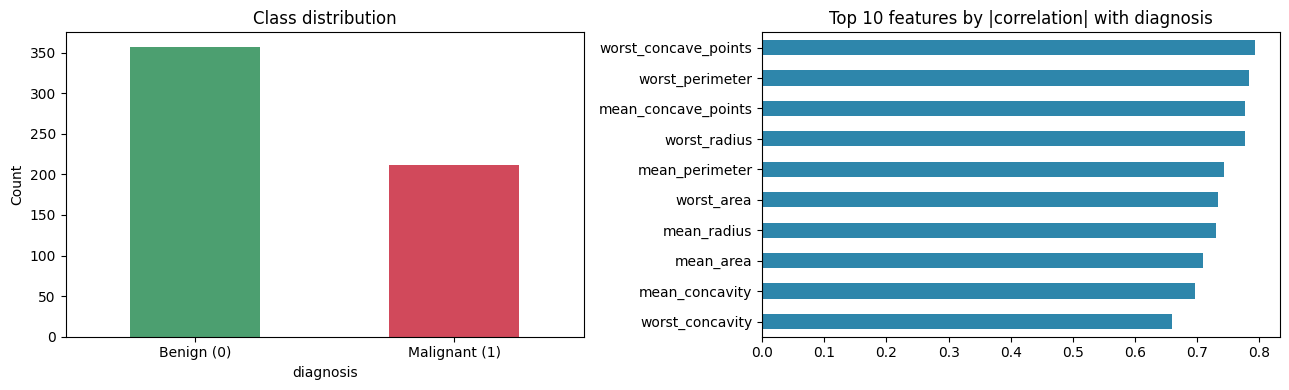

In [5]:
#class counts
print('Missing values:', df.isnull().sum().sum())
counts = df['diagnosis'].value_counts().sort_index().rename({0: 'Benign (0)', 1: 'Malignant (1)'})
print(counts)

#class distribution
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts.plot(kind='bar', ax=ax[0], color=['#4C9F70', '#D1495B'])
ax[0].set_title('Class distribution')
ax[0].set_ylabel('Count')
ax[0].tick_params(axis='x', rotation=0)

#top 10 features by correlation with target
top = df.corr()['diagnosis'].drop('diagnosis').abs().sort_values(ascending=False).head(10)
top.plot(kind='barh', ax=ax[1], color='#2E86AB')
ax[1].set_title('Top 10 features by |correlation| with diagnosis')
ax[1].invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Train / test split

80/20 stratified split, saved with raw features and `diagnosis`.
- `train_data.csv`: used to train the models.
- `test_data.csv`: used for all metrics and for upload in the Streamlit app.

In [6]:
#features and target
X = df.drop(columns='diagnosis')
y = df['diagnosis']

#80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

#save train set
train_df = X_train.copy()
train_df['diagnosis'] = y_train
train_df.to_csv('train_data.csv', index=False)

#save test set
test_df = X_test.copy()
test_df['diagnosis'] = y_test
test_df.to_csv('test_data.csv', index=False)

#split summary
split_summary = pd.DataFrame({
    'File':          ['train_data.csv', 'test_data.csv', 'Total'],
    'Rows':          [len(train_df), len(test_df), len(train_df) + len(test_df)],
    'Columns':       [train_df.shape[1], test_df.shape[1], df.shape[1]],
    'Benign (0)':    [int((y_train == 0).sum()), int((y_test == 0).sum()), int((y == 0).sum())],
    'Malignant (1)': [int((y_train == 1).sum()), int((y_test == 1).sum()), int((y == 1).sum())],
})
split_summary['% of data'] = (split_summary['Rows'] / len(df) * 100).round(1)
split_summary['% Malignant'] = (split_summary['Malignant (1)'] / split_summary['Rows'] * 100).round(1)
display(split_summary.set_index('File'))

#no rows lost in split
assert len(train_df) + len(test_df) == len(df)
print('Saved train_data.csv and test_data.csv')

,Rows,Columns,Benign (0),Malignant (1),% of data,% Malignant
File,,,,,,
train_data.csv,455,31,285,170,80.0,37.4
test_data.csv,114,31,72,42,20.0,36.8
Total,569,31,357,212,100.0,37.3


Saved train_data.csv and test_data.csv


## 5. Define the 5 models

Each model is a `StandardScaler` → classifier pipeline, so scaling is saved with the model.

In [7]:
#scaler + classifier
def make_pipeline(clf):
    return Pipeline([('scaler', StandardScaler()), ('clf', clf)])

#5 classifiers
models = {
    'Logistic Regression':    make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    'Decision Tree':          make_pipeline(DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)),
    'KNN':                    make_pipeline(KNeighborsClassifier(n_neighbors=5)),
    'Naive Bayes':            make_pipeline(GaussianNB()),
    'Support Vector Machine': make_pipeline(SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)),
}

## 6. Train and evaluate

Train on `train_data.csv` (455 rows), evaluate on `test_data.csv` (114 rows).

In [8]:
#all 6 metrics for one model
def evaluate(model, X, y):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]   #P(malignant), for AUC
    return {
        'Accuracy':  accuracy_score(y, y_pred),
        'AUC':       roc_auc_score(y, y_prob),
        'Precision': precision_score(y, y_pred),
        'Recall':    recall_score(y, y_pred),
        'F1':        f1_score(y, y_pred),
        'MCC':       matthews_corrcoef(y, y_pred),
    }

print(f'Training on {X_train.shape[0]} rows x {X_train.shape[1]} features, '
      f'testing on {X_test.shape[0]} rows')

#train and score each model
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = evaluate(model, X_test, y_test)

#comparison table
results_df = pd.DataFrame(results).T.round(4)
results_df.index.name = 'ML Model Name'
display(results_df)

Training on 455 rows x 30 features, testing on 114 rows


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
Decision Tree,0.9211,0.9448,0.9459,0.8333,0.8861,0.8299
KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
Naive Bayes,0.9211,0.9891,0.9231,0.8571,0.8889,0.8292
Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


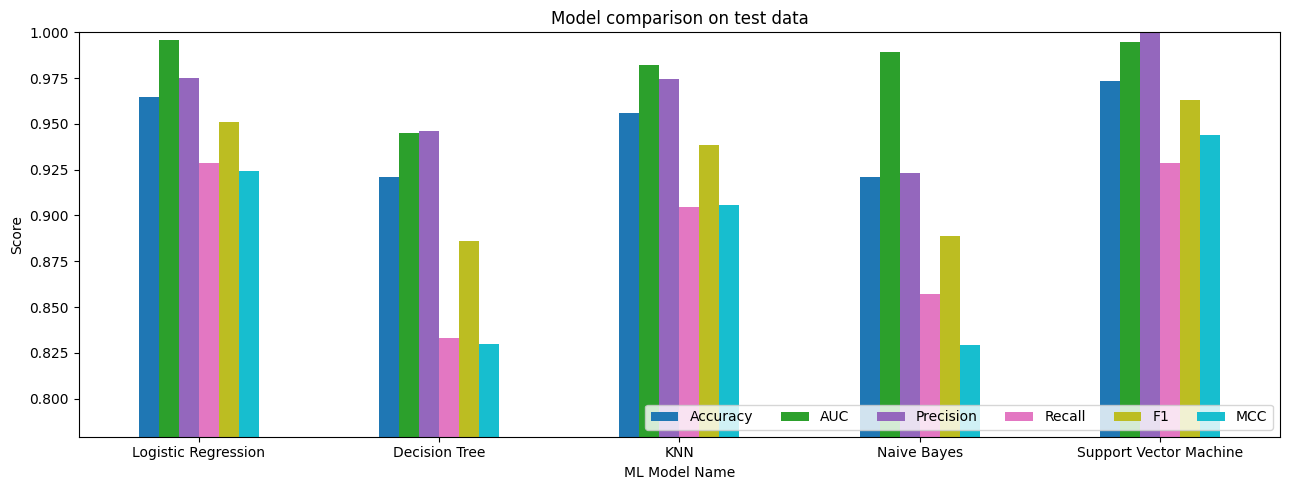

In [9]:
#metric comparison chart
low = max(0, results_df.values.min() - 0.05)
results_df.plot(kind='bar', figsize=(13, 5), ylim=(low, 1.0), colormap='tab10')
plt.title('Model comparison on test data')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right', ncol=6)
plt.tight_layout()
plt.show()

## 7. Confusion matrices and classification reports

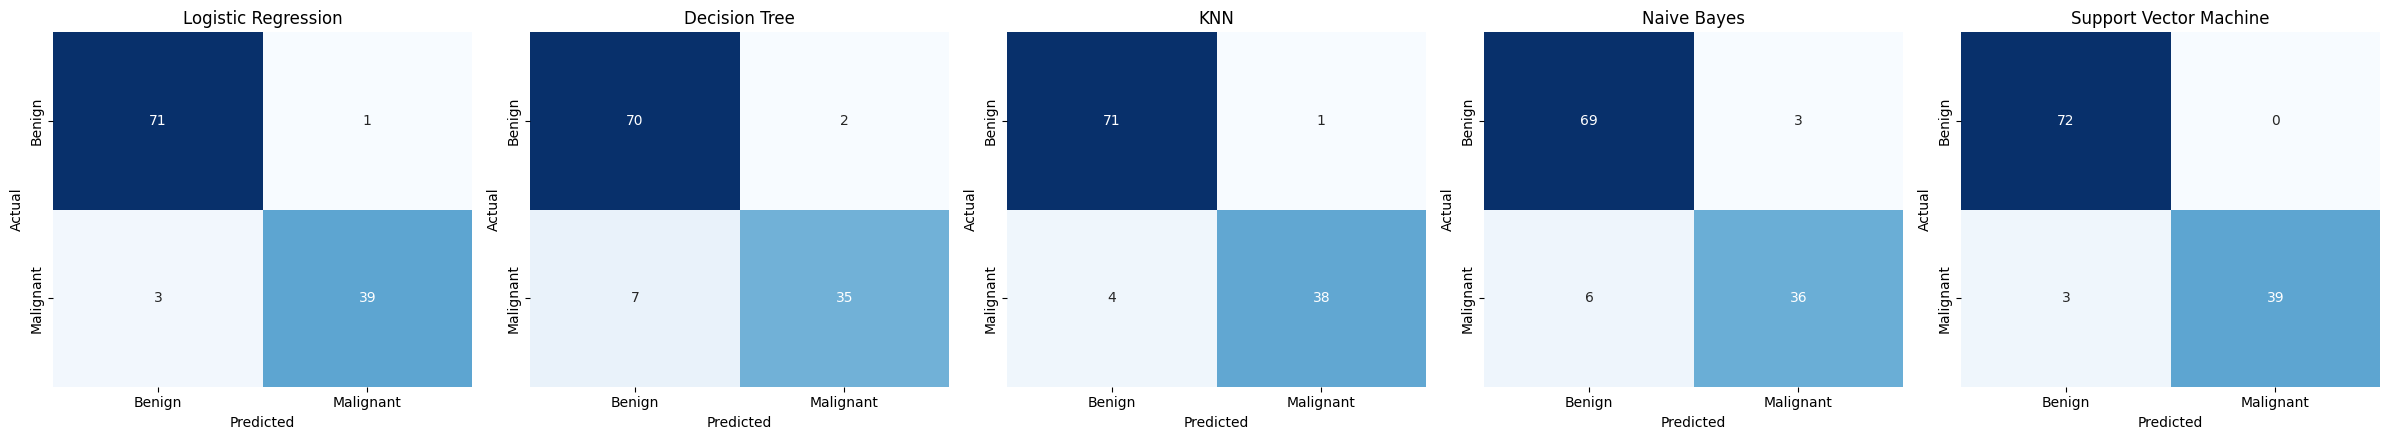

==================== Logistic Regression ====================
              precision    recall  f1-score   support

      Benign     0.9595    0.9861    0.9726        72
   Malignant     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114

==================== Decision Tree ====================
              precision    recall  f1-score   support

      Benign     0.9091    0.9722    0.9396        72
   Malignant     0.9459    0.8333    0.8861        42

    accuracy                         0.9211       114
   macro avg     0.9275    0.9028    0.9128       114
weighted avg     0.9227    0.9211    0.9199       114

==================== KNN ====================
              precision    recall  f1-score   support

      Benign     0.9467    0.9861    0.9660        72
   Malignant     0.9744    0.9048    0.9383        42

    accuracy      

In [10]:
#confusion matrix for each model
labels = ['Benign', 'Malignant']
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

#classification report for each model
for name, model in models.items():
    print('=' * 20, name, '=' * 20)
    print(classification_report(y_test, model.predict(X_test), target_names=labels, digits=4))

## 8. Save trained models to model/

In [11]:
#save each model as .pkl
os.makedirs('model', exist_ok=True)
file_names = {}
for name, model in models.items():
    fname = name.lower().replace(' ', '_') + '.pkl'
    joblib.dump(model, os.path.join('model', fname))
    file_names[name] = fname

#metadata used by the app
metadata = {
    'dataset': 'Breast Cancer Wisconsin (Diagnostic)',
    'dataset_url': DATASET_URL,
    'n_rows_total': int(len(df)),
    'n_rows_train': int(len(train_df)),
    'n_rows_test': int(len(test_df)),
    'n_features': int(X.shape[1]),
    'feature_names': list(X.columns),
    'target': 'diagnosis',
    'class_labels': {'0': 'Benign', '1': 'Malignant'},
    'models': file_names,
    'sklearn_version': sklearn.__version__,
}
with open('model/metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

#save metrics table
results_df.to_csv('model/metrics.csv')
print(sorted(os.listdir('model')))

['decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'metadata.json', 'metrics.csv', 'naive_bayes.pkl', 'support_vector_machine.pkl']


## 9. Reload check

Load the saved models and score `test_data.csv` without retraining.

In [12]:
#reload saved csv files
check = pd.read_csv('test_data.csv')
train_check = pd.read_csv('train_data.csv')
print(f'train_data.csv: {train_check.shape[0]} rows x {train_check.shape[1]} columns')
print(f'test_data.csv : {check.shape[0]} rows x {check.shape[1]} columns')
print()

#load each model and score test set
for name, fname in file_names.items():
    m = joblib.load(os.path.join('model', fname))
    acc = accuracy_score(check['diagnosis'], m.predict(check.drop(columns='diagnosis')))
    print(f'{name:<25} reloaded accuracy = {acc:.4f}')

train_data.csv: 455 rows x 31 columns
test_data.csv : 114 rows x 31 columns

Logistic Regression       reloaded accuracy = 0.9649
Decision Tree             reloaded accuracy = 0.9211
KNN                       reloaded accuracy = 0.9561
Naive Bayes               reloaded accuracy = 0.9211
Support Vector Machine    reloaded accuracy = 0.9737


## 10. Summary output

In [13]:
#dataset summary
print('--- Dataset ---')
print(f'Rows: {len(df)} | Columns: {df.shape[1]} | Features: {X.shape[1]} | '
      f'Train: {len(train_df)} | Test: {len(test_df)}')
print()

#metrics as markdown table
print('--- Paste into README comparison table ---')
print()
print('| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |')
print('|---|---|---|---|---|---|---|')
for name, row in results_df.iterrows():
    print(f'| {name} | ' + ' | '.join(f'{v:.4f}' for v in row.values) + ' |')

print()
print('Best model by MCC:', results_df['MCC'].idxmax())
print()

#requirements with current sklearn version
print('--- requirements.txt ---')
print()
print('streamlit')
print(f'scikit-learn=={sklearn.__version__}')
print('numpy')
print('pandas')
print('matplotlib')
print('seaborn')
print('joblib')

--- Dataset ---
Rows: 569 | Columns: 31 | Features: 30 | Train: 455 | Test: 114

--- Paste into README comparison table ---

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9649 | 0.9960 | 0.9750 | 0.9286 | 0.9512 | 0.9245 |
| Decision Tree | 0.9211 | 0.9448 | 0.9459 | 0.8333 | 0.8861 | 0.8299 |
| KNN | 0.9561 | 0.9823 | 0.9744 | 0.9048 | 0.9383 | 0.9058 |
| Naive Bayes | 0.9211 | 0.9891 | 0.9231 | 0.8571 | 0.8889 | 0.8292 |
| Support Vector Machine | 0.9737 | 0.9947 | 1.0000 | 0.9286 | 0.9630 | 0.9442 |

Best model by MCC: Support Vector Machine

--- requirements.txt ---

streamlit
scikit-learn==1.6.1
numpy
pandas
matplotlib
seaborn
joblib


## 11. Download outputs (train_data.csv + test_data.csv + model/)

In [14]:
#zip csv files and models
with zipfile.ZipFile('ml_assignment_outputs.zip', 'w') as z:
    z.write('train_data.csv')
    z.write('test_data.csv')
    for f in sorted(os.listdir('model')):
        z.write(os.path.join('model', f))

#download in colab, else keep locally
try:
    from google.colab import files
    files.download('ml_assignment_outputs.zip')
except ImportError:
    print('Not running on Colab: ml_assignment_outputs.zip saved in the current folder.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>